# Klasifikasi Tumor Otak MRI: VGG-16, ResNet-101, GoogLeNet (revisi)

**Cara pakai:** jalankan seluruh notebook dari atas ke bawah. Notebook ini membuat split acak terstratifikasi dari gabungan folder `Training` dan `Testing`, sesuai rancangan eksperimen. Duplikat file yang identik persis dibuang sebelum split.

Revisi utama:
- Resize memakai **padding hitam** agar rasio aspek gambar tetap terjaga.
- Hasil disimpan ke folder eksperimen baru `results_final_padded_lr1e-3`, jadi tidak tercampur dengan hasil versi sebelumnya.
- Hasil lama hanya dimuat jika konfigurasi dan identitas data/split cocok.
- Sel bootstrap memuat prediksi secara eksplisit; ditambahkan bootstrap berpasangan dan uji McNemar exact.

Split ini adalah split acak baru dari gabungan kedua folder, bukan evaluasi pada folder `Testing` resmi.


## 0. Import & Konfigurasi

In [1]:
import os, sys, copy, time, json, random, hashlib, shutil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from sklearn.model_selection import train_test_split
from scipy.stats import binomtest

# --- Lokasi project ---
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT_DIR = "/content/drive/MyDrive/Skripsi"  # berisi folder dataset
else:
    PROJECT_DIR = r"D:\Skripsi"

if os.path.isdir(PROJECT_DIR):
    os.chdir(PROJECT_DIR)
print("Working directory:", os.getcwd())

# --- Lokasi dataset ---
DATA_DIR = "dataset"
if IN_COLAB:
    # Salin dataset ke disk lokal Colab agar pembacaan gambar lebih cepat.
    LOCAL_DATA = "/content/dataset"
    if not os.path.isdir(LOCAL_DATA):
        print("Menyalin dataset dari Drive ke disk lokal Colab (sekali saja)...")
        shutil.copytree(os.path.join(PROJECT_DIR, "dataset"), LOCAL_DATA)
    DATA_DIR = LOCAL_DATA


Working directory: D:\Skripsi


In [2]:
# ===== KONFIGURASI EKSPERIMEN =====
IMG_SIZE = 224
BATCH_SIZE = 32

LR_BEFORE = 1e-3          # tahap 1: classifier head saja
LR_FT = 1e-4              # tahap 2: fine-tuning
EARLY_STOP_PATIENCE = 5
MAX_EPOCHS = 30
ROTATION_DEG = 15
SEED = 42

# Folder baru supaya hasil sebelum padding tidak ikut terbaca sebagai hasil revisi.
BASE_DIR = PROJECT_DIR if os.path.isdir(PROJECT_DIR) else "."
RESULTS_DIR = os.path.join(BASE_DIR, "results_final_padded_lr1e-3")
os.makedirs(RESULTS_DIR, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
NUM_WORKERS = 2 if DEVICE.type == "cuda" else 0
PIN_MEMORY = DEVICE.type == "cuda"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if DEVICE.type == "cuda":
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

EXPERIMENT_CONFIG = {
    "version": "padded_lr1e-3_v1",
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "lr_before": LR_BEFORE,
    "lr_finetune": LR_FT,
    "early_stop_patience": EARLY_STOP_PATIENCE,
    "max_epochs": MAX_EPOCHS,
    "rotation_degrees": ROTATION_DEG,
    "seed": SEED,
    "split": "combined_pool_deduplicated_stratified_80_10_10",
    "resize": "aspect_preserving_centered_black_padding",
}

print("Torch version :", torch.__version__)
print("Device        :", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")
print("LR tahap 1    :", LR_BEFORE, "| LR fine-tuning:", LR_FT)
print("Folder hasil  :", RESULTS_DIR)


Torch version : 2.11.0+cpu
Device        : cpu | CPU
LR tahap 1    : 0.001 | LR fine-tuning: 0.0001
Folder hasil  : D:\Skripsi\results_final_padded_lr1e-3


## Eksplorasi Data

In [3]:
TRAIN_DIR = os.path.join(DATA_DIR, "Training")
TEST_DIR = os.path.join(DATA_DIR, "Testing")

def count_images_per_class(folder_path):
    counts = {}
    for class_name in sorted(os.listdir(folder_path)):
        class_path = os.path.join(folder_path, class_name)
        if os.path.isdir(class_path):
            counts[class_name] = len([
                f for f in os.listdir(class_path)
                if f.lower().endswith((".jpg", ".jpeg", ".png"))
            ])
    return counts

df_counts = pd.DataFrame({
    "Training": count_images_per_class(TRAIN_DIR),
    "Testing": count_images_per_class(TEST_DIR)
}).fillna(0).astype(int)
df_counts["Total"] = df_counts["Training"] + df_counts["Testing"]
df_counts["Persentase (%)"] = (df_counts["Total"] / df_counts["Total"].sum() * 100).round(2)
df_counts.loc["TOTAL"] = df_counts.sum()
df_counts

,Training,Testing,Total,Persentase (%)
glioma,1400.0,400.0,1800.0,25.0
meningioma,1400.0,400.0,1800.0,25.0
notumor,1400.0,400.0,1800.0,25.0
pituitary,1400.0,400.0,1800.0,25.0
TOTAL,5600.0,1600.0,7200.0,100.0


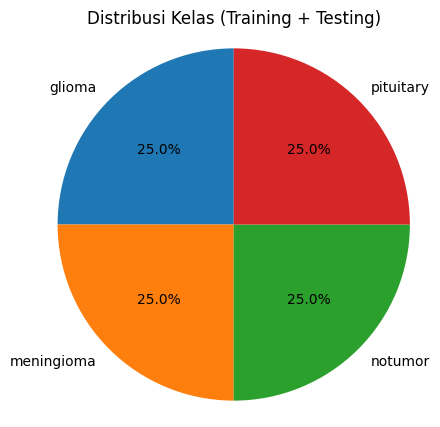

In [4]:
class_only = df_counts.drop(index="TOTAL")
plt.figure(figsize=(5, 5))
plt.pie(class_only["Total"], labels=class_only.index, autopct="%1.1f%%", startangle=90)
plt.title("Distribusi Kelas (Training + Testing)")
plt.axis("equal")
plt.show()

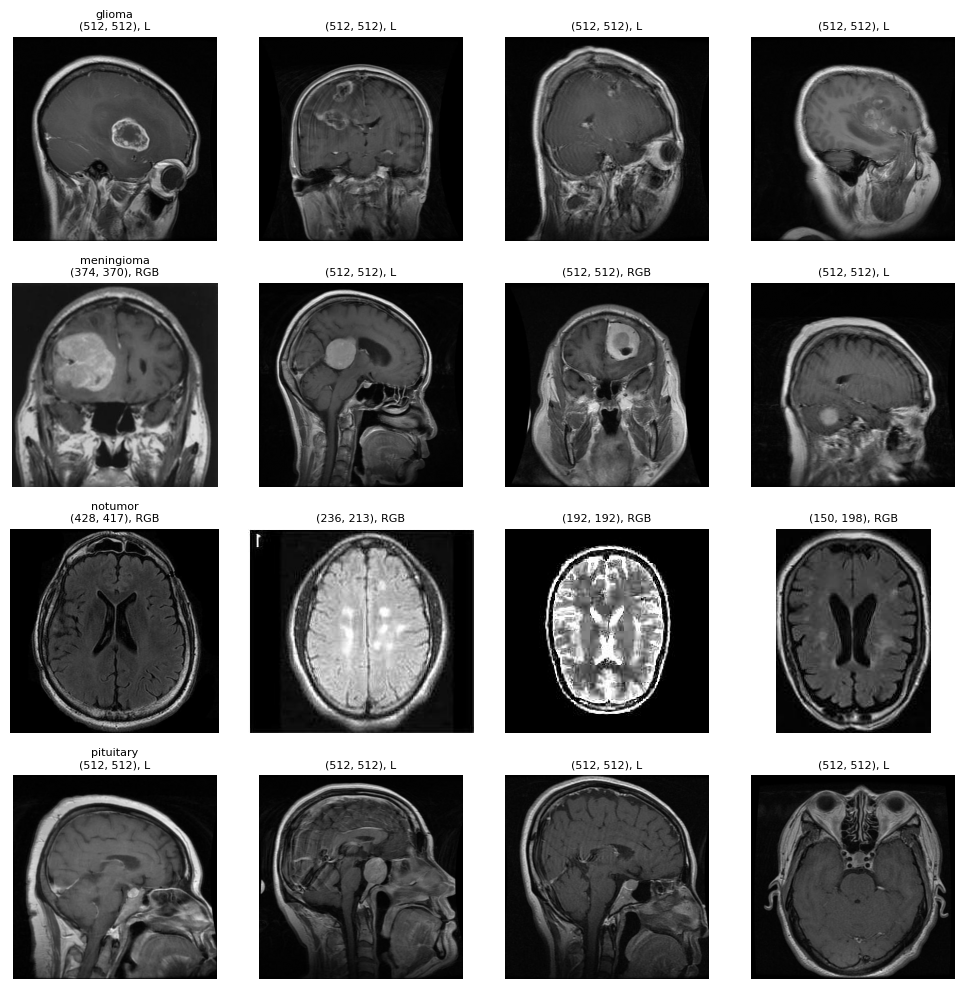

In [5]:
def show_sample_images(folder_path, n_per_class=4):
    class_names_ = sorted(os.listdir(folder_path))
    fig, axes = plt.subplots(len(class_names_), n_per_class,
                             figsize=(n_per_class * 2.5, len(class_names_) * 2.5))
    for row, cname in enumerate(class_names_):
        cpath = os.path.join(folder_path, cname)
        files = [f for f in os.listdir(cpath) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
        for col, fname in enumerate(random.sample(files, min(n_per_class, len(files)))):
            img = Image.open(os.path.join(cpath, fname))
            ax = axes[row, col]
            ax.imshow(img, cmap="gray")
            ax.axis("off")
            ax.set_title(f"{cname}\n{img.size}, {img.mode}" if col == 0 else f"{img.size}, {img.mode}", fontsize=8)
    plt.tight_layout()
    plt.show()

show_sample_images(TRAIN_DIR, n_per_class=4)

In [6]:
# Cek ukuran & mode warna (sampel 200 gambar per kelas)
sizes, modes = set(), set()
for cname in sorted(os.listdir(TRAIN_DIR)):
    cpath = os.path.join(TRAIN_DIR, cname)
    for fname in os.listdir(cpath)[:200]:
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            with Image.open(os.path.join(cpath, fname)) as img:
                sizes.add(img.size)
                modes.add(img.mode)
print("Ukuran unik     :", sizes)
print("Mode warna unik :", modes)

Ukuran unik     : {(420, 280), (206, 244), (800, 693), (393, 400), (387, 469), (200, 252), (201, 251), (453, 496), (318, 354), (441, 442), (236, 226), (470, 432), (1275, 1427), (150, 198), (227, 262), (528, 528), (203, 243), (207, 243), (234, 224), (890, 1075), (208, 278), (442, 454), (232, 217), (374, 456), (236, 269), (296, 320), (626, 686), (276, 326), (256, 256), (359, 449), (201, 250), (257, 248), (192, 192), (538, 548), (236, 280), (225, 225), (262, 244), (410, 490), (275, 183), (366, 395), (218, 231), (680, 680), (350, 350), (214, 236), (442, 442), (173, 201), (230, 235), (1338, 1304), (236, 220), (497, 398), (216, 293), (236, 250), (494, 600), (210, 240), (228, 221), (755, 824), (236, 213), (234, 225), (504, 540), (227, 222), (235, 244), (236, 252), (350, 393), (416, 512), (630, 630), (405, 484), (275, 301), (236, 236), (512, 512), (212, 238), (215, 234), (196, 257), (236, 357), (226, 212), (236, 366), (339, 415), (428, 417), (354, 443), (468, 444), (194, 259), (642, 361), (177

## Muat Data & Cek Duplikat

Training + Testing digabung jadi satu pool. Setiap file dihitung hash-nya untuk mendeteksi gambar identik persis,
baik di dalam satu folder maupun lintas folder.

In [7]:
train_folder_raw = datasets.ImageFolder(TRAIN_DIR, transform=None)
test_folder_raw = datasets.ImageFolder(TEST_DIR, transform=None)

class_names = train_folder_raw.classes
assert train_folder_raw.classes == test_folder_raw.classes, "Urutan kelas Training dan Testing harus sama!"
print("Kelas (urutan index):", class_names)

# Urutan all_samples sama persis dengan urutan index di ConcatDataset
all_samples = train_folder_raw.samples + test_folder_raw.samples      # list of (path, label)
combined_dataset = torch.utils.data.ConcatDataset([train_folder_raw, test_folder_raw])
n_train_orig = len(train_folder_raw.samples)
print("Total gambar pool gabungan:", len(all_samples))

with open(os.path.join(RESULTS_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

Kelas (urutan index): ['glioma', 'meningioma', 'notumor', 'pituitary']
Total gambar pool gabungan: 7200


In [8]:
def md5_of(path):
    with open(path, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

print("Menghitung hash semua file (sekitar 1-2 menit)...")
all_hashes = [md5_of(p) for p, _ in all_samples]

hash_groups = {}
for idx, h in enumerate(all_hashes):
    hash_groups.setdefault(h, []).append(idx)

dup_groups = {h: ix for h, ix in hash_groups.items() if len(ix) > 1}
n_extra_copies = sum(len(ix) - 1 for ix in dup_groups.values())

cross = [ix for ix in dup_groups.values()
         if any(i < n_train_orig for i in ix) and any(i >= n_train_orig for i in ix)]
label_conflict = [ix for ix in dup_groups.values() if len({all_samples[i][1] for i in ix}) > 1]

print(f"File total                       : {len(all_samples)}")
print(f"File unik (hash berbeda)         : {len(hash_groups)}")
print(f"Kelompok gambar duplikat         : {len(dup_groups)}")
print(f"Salinan berlebih (akan dibuang)  : {n_extra_copies}")
print(f"Duplikat lintas Training-Testing : {len(cross)} kelompok")
print(f"Duplikat dengan label berbeda    : {len(label_conflict)} kelompok")

Menghitung hash semua file (sekitar 1-2 menit)...
File total                       : 7200
File unik (hash berbeda)         : 7013
Kelompok gambar duplikat         : 153
Salinan berlebih (akan dibuang)  : 187
Duplikat lintas Training-Testing : 0 kelompok
Duplikat dengan label berbeda    : 0 kelompok


## Transform & Augmentasi

Augmentasi diterapkan secara dinamis hanya pada data train. Gambar diubah ukurannya dengan **mempertahankan rasio aspek**, lalu ruang kosong diisi padding hitam hingga berukuran 224×224. Dengan begitu, gambar tidak diregangkan ke bentuk persegi.


In [9]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

class ResizeWithPad:
    """Ubah ukuran tanpa distorsi, lalu pad di tengah hingga menjadi persegi."""
    def __init__(self, size, fill=0):
        self.size = (size, size) if isinstance(size, int) else tuple(size)
        self.fill = fill

    def __call__(self, image):
        return ImageOps.pad(
            image,
            self.size,
            method=Image.Resampling.BICUBIC,
            color=self.fill,
            centering=(0.5, 0.5),
        )

resize_with_pad = ResizeWithPad(IMG_SIZE, fill=0)

train_transform = transforms.Compose([
    resize_with_pad,
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=ROTATION_DEG, fill=0),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])

eval_transform = transforms.Compose([
    resize_with_pad,
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std),
])
print("Transform siap: rasio aspek dipertahankan dan padding di tengah.")


Transform siap: rasio aspek dipertahankan dan padding di tengah.


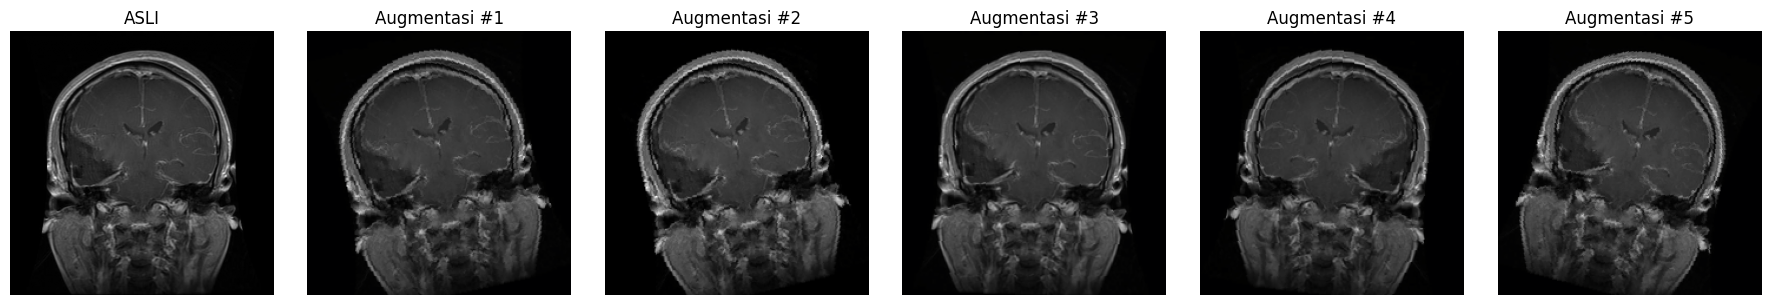

In [10]:
# Demo: 1 file asli -> beberapa tampilan hasil augmentasi (jumlah file tetap)
sample_path, _ = all_samples[0]
original_img = Image.open(sample_path)

n_versions = 5
fig, axes = plt.subplots(1, n_versions + 1, figsize=(3 * (n_versions + 1), 3))
axes[0].imshow(original_img, cmap="gray")
axes[0].set_title("ASLI")
axes[0].axis("off")
for i in range(1, n_versions + 1):
    t = train_transform(original_img)
    im = np.clip(np.array(imagenet_std) * t.permute(1, 2, 0).numpy() + np.array(imagenet_mean), 0, 1)
    axes[i].imshow(im)
    axes[i].set_title(f"Augmentasi #{i}")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

## Buang Duplikat & Split Stratified 80:10:10

1. Dari setiap kelompok gambar identik, hanya **1 salinan** dipertahankan.
2. Split **stratified** (proporsi tiap kelas sama di train/val/test).
3. Dicek otomatis bahwa tidak ada gambar identik di dua subset berbeda.

In [11]:
# 1) Buang duplikat: pertahankan salinan pertama tiap hash
unique_idx = sorted(ix[0] for ix in hash_groups.values())
unique_labels = [all_samples[i][1] for i in unique_idx]
print(f"Sebelum dedup: {len(all_samples)} | Sesudah dedup: {len(unique_idx)}")

# 2) Split stratified 80 / 10 / 10
train_indices, temp_idx = train_test_split(
    unique_idx, test_size=0.20, stratify=unique_labels, random_state=SEED)
temp_labels = [all_samples[i][1] for i in temp_idx]
val_indices, test_indices = train_test_split(
    temp_idx, test_size=0.50, stratify=temp_labels, random_state=SEED)

n_all = len(unique_idx)
print(f"Train: {len(train_indices)} ({len(train_indices)/n_all*100:.1f}%)")
print(f"Val  : {len(val_indices)} ({len(val_indices)/n_all*100:.1f}%)")
print(f"Test : {len(test_indices)} ({len(test_indices)/n_all*100:.1f}%)")

# 3) Cek: tidak ada hash yang sama antar subset
h_train = {all_hashes[i] for i in train_indices}
h_val = {all_hashes[i] for i in val_indices}
h_test = {all_hashes[i] for i in test_indices}
assert not (h_train & h_val), "Ada gambar identik di train dan val!"
assert not (h_train & h_test), "Ada gambar identik di train dan test!"
assert not (h_val & h_test), "Ada gambar identik di val dan test!"
print("Cek kebocoran duplikat antar subset: AMAN (tidak ada gambar identik lintas subset)")

def dist(indices):
    labs = [class_names[all_samples[i][1]] for i in indices]
    return pd.Series(labs).value_counts().reindex(class_names)

split_distribution = pd.DataFrame({
    "Train": dist(train_indices),
    "Val": dist(val_indices),
    "Test": dist(test_indices),
})
print(split_distribution)

# Sidik eksperimen mencegah metrik dari data/split/konfigurasi lain dimuat tanpa sengaja.
dataset_identity = [(all_hashes[i], all_samples[i][1]) for i in range(len(all_samples))]
dataset_digest = hashlib.sha256(
    json.dumps(dataset_identity, separators=(",", ":")).encode("utf-8")
).hexdigest()
split_payload = {
    "train": train_indices,
    "val": val_indices,
    "test": test_indices,
}
split_digest = hashlib.sha256(
    json.dumps(split_payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
).hexdigest()
EXPERIMENT_SIGNATURE = hashlib.sha256(
    json.dumps({
        "config": EXPERIMENT_CONFIG,
        "dataset_digest": dataset_digest,
        "split_digest": split_digest,
        "classes": class_names,
    }, sort_keys=True, separators=(",", ":")).encode("utf-8")
).hexdigest()
print("Fingerprint data/split:", EXPERIMENT_SIGNATURE[:16])

Sebelum dedup: 7200 | Sesudah dedup: 7013
Train: 5610 (80.0%)
Val  : 701 (10.0%)
Test : 702 (10.0%)
Cek kebocoran duplikat antar subset: AMAN (tidak ada gambar identik lintas subset)
            Train  Val  Test
glioma       1429  178   179
meningioma   1427  178   179
notumor      1345  168   168
pituitary    1409  177   176
Fingerprint data/split: b63a80d29d563338


In [12]:
class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, base_dataset, indices, transform):
        self.base_dataset = base_dataset
        self.indices = indices
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, label = self.base_dataset[self.indices[idx]]
        if self.transform is not None:
            img = self.transform(img)
        return img, label

train_dataset = TransformSubset(combined_dataset, train_indices, train_transform)
val_dataset = TransformSubset(combined_dataset, val_indices, eval_transform)
test_dataset = TransformSubset(combined_dataset, test_indices, eval_transform)

loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=PIN_MEMORY)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)

images, labels = next(iter(train_loader))
print("Shape 1 batch:", images.shape, "| label:", labels[:10].tolist())

Shape 1 batch: torch.Size([32, 3, 224, 224]) | label: [3, 2, 0, 0, 3, 1, 0, 1, 2, 0]


## Bangun Model (Transfer Learning)

Tahap 1: backbone dibekukan, hanya classifier head yang dilatih.
Tahap 2: lapisan terdalam dibuka untuk fine-tuning.

In [13]:
NUM_CLASSES = len(class_names)

def build_model(arch, num_classes=NUM_CLASSES):
    if arch == "vgg16":
        model = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1)
        for p in model.parameters():
            p.requires_grad = False
        model.classifier[6] = nn.Linear(model.classifier[6].in_features, num_classes)

    elif arch == "resnet101":
        model = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V2)
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    elif arch == "googlenet":
        model = models.googlenet(weights=models.GoogLeNet_Weights.IMAGENET1K_V1)
        model.aux_logits = False
        model.aux1 = None
        model.aux2 = None
        for p in model.parameters():
            p.requires_grad = False
        model.fc = nn.Linear(model.fc.in_features, num_classes)

    else:
        raise ValueError(f"Arsitektur tidak dikenal: {arch}")

    return model.to(DEVICE)


def unfreeze_deep_layers(model, arch):
    # Buka lapisan konvolusi terdalam untuk fine-tuning
    if arch == "vgg16":
        for name, p in model.named_parameters():
            if name.startswith(("features.24", "features.26", "features.28", "classifier")):
                p.requires_grad = True
    elif arch == "resnet101":
        for name, p in model.named_parameters():
            if name.startswith(("layer4", "fc")):
                p.requires_grad = True
    elif arch == "googlenet":
        for name, p in model.named_parameters():
            if name.startswith(("inception5", "fc")):
                p.requires_grad = True
    return model


def set_bn_eval(model):
    # Bekukan statistik BatchNorm (running mean/var). Tanpa ini, BatchNorm pada backbone
    # yang "dibeku" tetap berubah tiap batch dan membuat val loss tidak stabil.
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            m.eval()

# Cek cepat jumlah parameter (VGG-16)
_m = build_model("vgg16")
print("Total parameter        :", f"{sum(p.numel() for p in _m.parameters()):,}")
print("Trainable (sebelum FT) :", f"{sum(p.numel() for p in _m.parameters() if p.requires_grad):,}")
del _m

Total parameter        : 134,276,932
Trainable (sebelum FT) : 16,388


## Fungsi Training, Evaluasi, Plot

In [14]:
def train_model(model, train_loader, val_loader, lr, max_epochs, patience, stage_name=""):
    criterion = nn.CrossEntropyLoss()
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = optim.Adam(trainable_params, lr=lr)

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    history = {"train_loss": [], "val_loss": [], "val_acc": []}

    for epoch in range(1, max_epochs + 1):
        t0 = time.time()

        model.train()
        set_bn_eval(model)          # statistik BatchNorm tidak ikut berubah
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * inputs.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_loss, correct = 0.0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                outputs = model(inputs)
                val_loss += criterion(outputs, labels).item() * inputs.size(0)
                correct += (outputs.argmax(dim=1) == labels).sum().item()
        val_loss /= len(val_loader.dataset)
        val_acc = correct / len(val_loader.dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(f"[{stage_name}] Epoch {epoch:02d} | train_loss={train_loss:.4f} "
              f"| val_loss={val_loss:.4f} | val_acc={val_acc:.4f} | {time.time()-t0:.1f}s")

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"[{stage_name}] Early stopping di epoch {epoch}.")
                break

    model.load_state_dict(best_state)
    return model, history

In [15]:
def evaluate_model(model, test_loader, class_names, stage_name=""):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            outputs = model(inputs.to(DEVICE))
            all_preds.extend(outputs.argmax(dim=1).cpu().numpy())
            all_labels.extend(labels.numpy())
    all_preds = np.array(all_preds)
    all_labels = np.array(all_labels)

    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average="macro", zero_division=0)
    rec = recall_score(all_labels, all_preds, average="macro", zero_division=0)
    f1 = f1_score(all_labels, all_preds, average="macro", zero_division=0)

    print(f"\n===== HASIL EVALUASI [{stage_name}] =====")
    print(f"Accuracy : {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall   : {rec:.4f}")
    print(f"F1-Score : {f1:.4f}\n")
    print(classification_report(all_labels, all_preds, target_names=class_names, zero_division=0))

    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(5, 4))
    plt.imshow(cm, cmap="Blues")
    plt.title(f"Confusion Matrix - {stage_name}")
    plt.colorbar()
    plt.xticks(range(len(class_names)), class_names, rotation=45)
    plt.yticks(range(len(class_names)), class_names)
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.ylabel("Label Asli")
    plt.xlabel("Label Prediksi")
    plt.tight_layout()
    plt.show()

    metrics = {"accuracy": acc, "precision": prec, "recall": rec, "f1": f1}
    return metrics, all_preds, all_labels


def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].plot(history["train_loss"], label="Train Loss")
    axes[0].plot(history["val_loss"], label="Val Loss")
    axes[0].set_title(f"Loss - {title}")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(history["val_acc"], label="Val Accuracy", color="green")
    axes[1].set_title(f"Val Accuracy - {title}")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## Pipeline per Arsitektur

In [16]:
def run_pipeline(arch):
    print(f"\n{'='*60}\nARSITEKTUR: {arch.upper()}\n{'='*60}")
    model = build_model(arch)

    print(">>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)")
    model, hist_before = train_model(
        model, train_loader, val_loader,
        lr=LR_BEFORE, max_epochs=MAX_EPOCHS, patience=EARLY_STOP_PATIENCE,
        stage_name=f"{arch}-before-FT"
    )
    plot_history(hist_before, title=f"{arch} - Sebelum Fine-Tuning")
    metrics_before, preds_before, labels_test = evaluate_model(
        model, test_loader, class_names, stage_name=f"{arch} - Sebelum FT")

    print(">>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)")
    model = unfreeze_deep_layers(model, arch)
    n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable parameter setelah unfreeze: {n_trainable:,}")

    model, hist_ft = train_model(
        model, train_loader, val_loader,
        lr=LR_FT, max_epochs=MAX_EPOCHS, patience=EARLY_STOP_PATIENCE,
        stage_name=f"{arch}-fine-tuning"
    )
    plot_history(hist_ft, title=f"{arch} - Fine-Tuning")
    metrics_after, preds_after, labels_after = evaluate_model(
        model, test_loader, class_names, stage_name=f"{arch} - Sesudah FT")
    assert np.array_equal(labels_test, labels_after), "Urutan label test berubah antar tahap."

    print(f"\nRingkasan {arch}:")
    print(f"  Sebelum FT -> F1: {metrics_before['f1']:.4f}, Accuracy: {metrics_before['accuracy']:.4f}")
    print(f"  Sesudah FT -> F1: {metrics_after['f1']:.4f}, Accuracy: {metrics_after['accuracy']:.4f}")
    print(f"  Peningkatan F1  : {metrics_after['f1'] - metrics_before['f1']:+.4f}")

    # Simpan artefak dahulu; manifest ditulis terakhir sebagai penanda bahwa satu model selesai.
    torch.save(model.state_dict(), os.path.join(RESULTS_DIR, f"{arch}_finetuned.pth"))
    np.savez(os.path.join(RESULTS_DIR, f"{arch}_preds.npz"),
             labels=labels_test, before=preds_before, after=preds_after)
    with open(os.path.join(RESULTS_DIR, f"{arch}_history.json"), "w", encoding="utf-8") as f:
        json.dump({"before": hist_before, "ft": hist_ft}, f)
    with open(os.path.join(RESULTS_DIR, f"{arch}_metrics.json"), "w", encoding="utf-8") as f:
        json.dump({"before": metrics_before, "after": metrics_after}, f, indent=2)
    with open(os.path.join(RESULTS_DIR, f"{arch}_manifest.json"), "w", encoding="utf-8") as f:
        json.dump({"signature": EXPERIMENT_SIGNATURE, "config": EXPERIMENT_CONFIG}, f, indent=2)

    return {"arch": arch, "before": metrics_before, "after": metrics_after}


def run_or_load(arch):
    paths = {
        "metrics": os.path.join(RESULTS_DIR, f"{arch}_metrics.json"),
        "history": os.path.join(RESULTS_DIR, f"{arch}_history.json"),
        "preds": os.path.join(RESULTS_DIR, f"{arch}_preds.npz"),
        "weights": os.path.join(RESULTS_DIR, f"{arch}_finetuned.pth"),
        "manifest": os.path.join(RESULTS_DIR, f"{arch}_manifest.json"),
    }
    complete = all(os.path.isfile(path) for path in paths.values())
    compatible = False
    if complete:
        with open(paths["manifest"], "r", encoding="utf-8") as f:
            compatible = json.load(f).get("signature") == EXPERIMENT_SIGNATURE

    if complete and compatible:
        print(f"[{arch}] Memuat hasil yang cocok dengan konfigurasi dan split ini.")
        with open(paths["metrics"], "r", encoding="utf-8") as f:
            m = json.load(f)
        return {"arch": arch, "before": m["before"], "after": m["after"]}

    if complete:
        print(f"[{arch}] Hasil lama tidak cocok; model ini akan dilatih ulang.")
    return run_pipeline(arch)


all_results = {}


## VGG-16



ARSITEKTUR: VGG16
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[vgg16-before-FT] Epoch 01 | train_loss=0.6826 | val_loss=0.5194 | val_acc=0.7874 | 942.4s
[vgg16-before-FT] Epoch 02 | train_loss=0.5621 | val_loss=0.4927 | val_acc=0.7917 | 901.0s
[vgg16-before-FT] Epoch 03 | train_loss=0.5328 | val_loss=0.5100 | val_acc=0.7917 | 901.1s
[vgg16-before-FT] Epoch 04 | train_loss=0.5314 | val_loss=0.4199 | val_acc=0.8402 | 908.2s
[vgg16-before-FT] Epoch 05 | train_loss=0.5360 | val_loss=0.4682 | val_acc=0.8146 | 887.2s
[vgg16-before-FT] Epoch 06 | train_loss=0.5285 | val_loss=0.4858 | val_acc=0.8160 | 873.2s
[vgg16-before-FT] Epoch 07 | train_loss=0.5198 | val_loss=0.3849 | val_acc=0.8645 | 871.2s
[vgg16-before-FT] Epoch 08 | train_loss=0.5456 | val_loss=0.5362 | val_acc=0.7874 | 873.4s
[vgg16-before-FT] Epoch 09 | train_loss=0.5253 | val_loss=0.3808 | val_acc=0.8516 | 899.9s
[vgg16-before-FT] Epoch 10 | train_loss=0.5456 | val_loss=0.3978 | val_acc=0.8488 | 933.8s
[vgg16

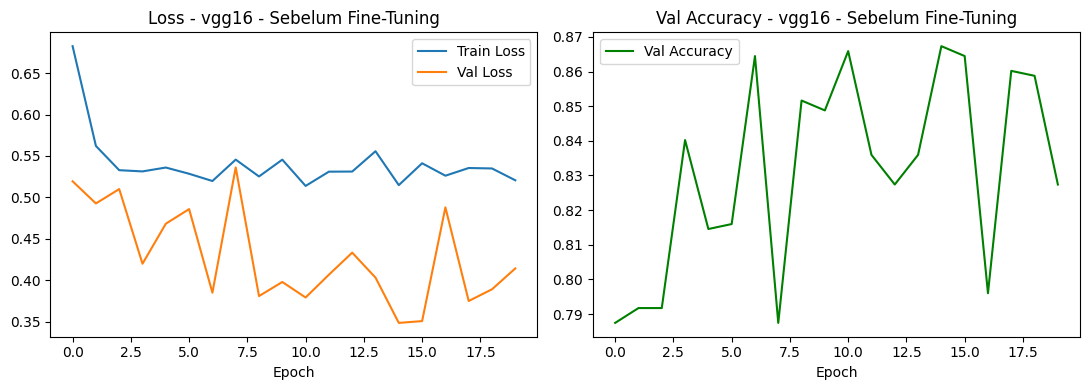


===== HASIL EVALUASI [vgg16 - Sebelum FT] =====
Accuracy : 0.8803
Precision: 0.8800
Recall   : 0.8820
F1-Score : 0.8804

              precision    recall  f1-score   support

      glioma       0.84      0.85      0.85       179
  meningioma       0.83      0.77      0.80       179
     notumor       0.91      0.97      0.94       168
   pituitary       0.94      0.94      0.94       176

    accuracy                           0.88       702
   macro avg       0.88      0.88      0.88       702
weighted avg       0.88      0.88      0.88       702



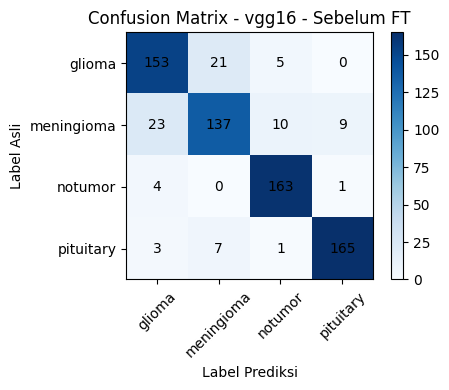

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 126,641,668
[vgg16-fine-tuning] Epoch 01 | train_loss=0.3920 | val_loss=0.2293 | val_acc=0.9201 | 1081.9s
[vgg16-fine-tuning] Epoch 02 | train_loss=0.1959 | val_loss=0.2721 | val_acc=0.9244 | 1111.1s
[vgg16-fine-tuning] Epoch 03 | train_loss=0.1486 | val_loss=0.2025 | val_acc=0.9387 | 1131.0s
[vgg16-fine-tuning] Epoch 04 | train_loss=0.1133 | val_loss=0.2763 | val_acc=0.9058 | 1085.5s
[vgg16-fine-tuning] Epoch 05 | train_loss=0.1107 | val_loss=0.1516 | val_acc=0.9501 | 1003.1s
[vgg16-fine-tuning] Epoch 06 | train_loss=0.0819 | val_loss=0.1730 | val_acc=0.9472 | 1022.7s
[vgg16-fine-tuning] Epoch 07 | train_loss=0.0667 | val_loss=0.1505 | val_acc=0.9658 | 1062.4s
[vgg16-fine-tuning] Epoch 08 | train_loss=0.0649 | val_loss=0.1151 | val_acc=0.9601 | 1053.7s
[vgg16-fine-tuning] Epoch 09 | train_loss=0.0473 | val_loss=0.1475 | val_acc=0.9643 | 1063.9s
[vgg16-fine-tuning] Epoch 10 | train_loss=0

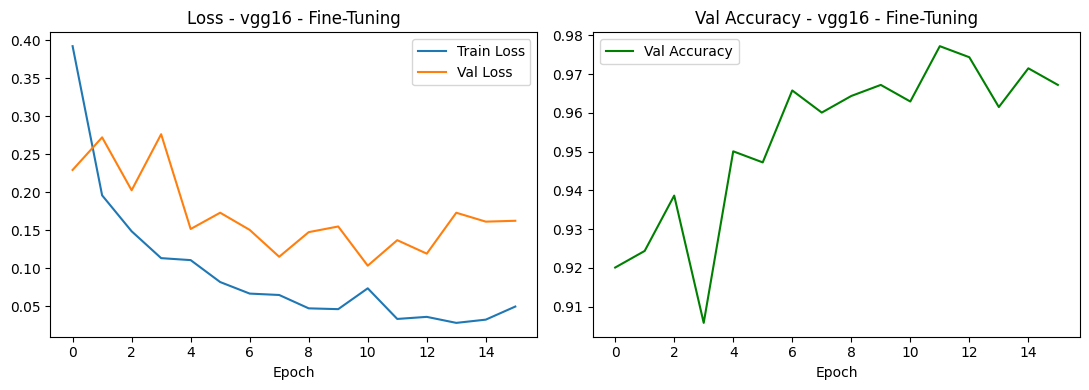


===== HASIL EVALUASI [vgg16 - Sesudah FT] =====
Accuracy : 0.9729
Precision: 0.9740
Recall   : 0.9731
F1-Score : 0.9732

              precision    recall  f1-score   support

      glioma       0.98      0.94      0.96       179
  meningioma       0.94      0.99      0.96       179
     notumor       0.99      0.98      0.99       168
   pituitary       0.98      0.97      0.98       176

    accuracy                           0.97       702
   macro avg       0.97      0.97      0.97       702
weighted avg       0.97      0.97      0.97       702



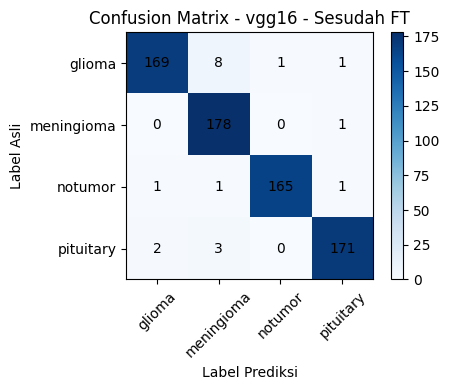


Ringkasan vgg16:
  Sebelum FT -> F1: 0.8804, Accuracy: 0.8803
  Sesudah FT -> F1: 0.9732, Accuracy: 0.9729
  Peningkatan F1  : +0.0929


In [17]:
all_results["vgg16"] = run_or_load("vgg16")

## ResNet-101


ARSITEKTUR: RESNET101
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[resnet101-before-FT] Epoch 01 | train_loss=0.6268 | val_loss=0.4477 | val_acc=0.8359 | 530.1s
[resnet101-before-FT] Epoch 02 | train_loss=0.4047 | val_loss=0.3888 | val_acc=0.8645 | 531.0s
[resnet101-before-FT] Epoch 03 | train_loss=0.3461 | val_loss=0.3421 | val_acc=0.8773 | 526.9s
[resnet101-before-FT] Epoch 04 | train_loss=0.3098 | val_loss=0.3167 | val_acc=0.8873 | 523.8s
[resnet101-before-FT] Epoch 05 | train_loss=0.2848 | val_loss=0.3000 | val_acc=0.8902 | 520.6s
[resnet101-before-FT] Epoch 06 | train_loss=0.2699 | val_loss=0.2858 | val_acc=0.9001 | 528.3s
[resnet101-before-FT] Epoch 07 | train_loss=0.2544 | val_loss=0.2858 | val_acc=0.9044 | 539.7s
[resnet101-before-FT] Epoch 08 | train_loss=0.2438 | val_loss=0.2667 | val_acc=0.8987 | 524.3s
[resnet101-before-FT] Epoch 09 | train_loss=0.2307 | val_loss=0.2588 | val_acc=0.9087 | 532.8s
[resnet101-before-FT] Epoch 10 | train_loss=0.2216 | val_

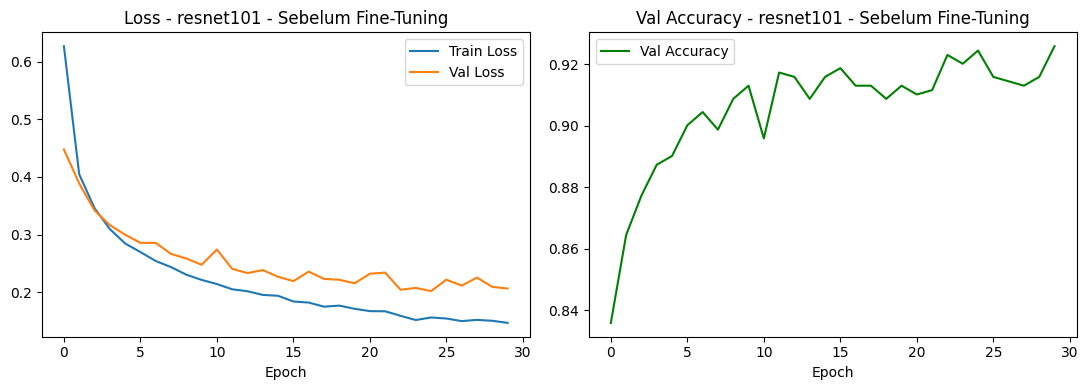


===== HASIL EVALUASI [resnet101 - Sebelum FT] =====
Accuracy : 0.9274
Precision: 0.9273
Recall   : 0.9283
F1-Score : 0.9277

              precision    recall  f1-score   support

      glioma       0.89      0.88      0.88       179
  meningioma       0.91      0.88      0.89       179
     notumor       0.96      0.98      0.97       168
   pituitary       0.96      0.98      0.97       176

    accuracy                           0.93       702
   macro avg       0.93      0.93      0.93       702
weighted avg       0.93      0.93      0.93       702



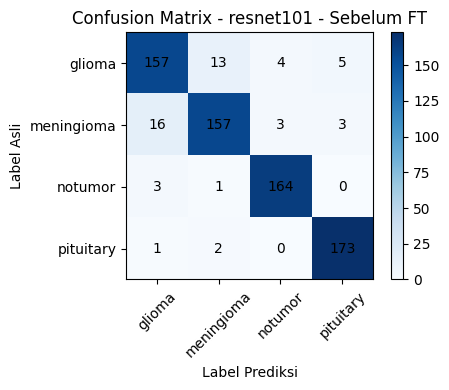

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 14,972,932
[resnet101-fine-tuning] Epoch 01 | train_loss=0.2361 | val_loss=0.2848 | val_acc=0.8959 | 593.1s
[resnet101-fine-tuning] Epoch 02 | train_loss=0.1311 | val_loss=0.2508 | val_acc=0.9244 | 597.8s
[resnet101-fine-tuning] Epoch 03 | train_loss=0.0891 | val_loss=0.1396 | val_acc=0.9572 | 598.5s
[resnet101-fine-tuning] Epoch 04 | train_loss=0.0642 | val_loss=0.1419 | val_acc=0.9615 | 598.8s
[resnet101-fine-tuning] Epoch 05 | train_loss=0.0621 | val_loss=0.1200 | val_acc=0.9700 | 602.3s
[resnet101-fine-tuning] Epoch 06 | train_loss=0.0415 | val_loss=0.1111 | val_acc=0.9686 | 597.8s
[resnet101-fine-tuning] Epoch 07 | train_loss=0.0429 | val_loss=0.1352 | val_acc=0.9658 | 601.6s
[resnet101-fine-tuning] Epoch 08 | train_loss=0.0388 | val_loss=0.1017 | val_acc=0.9757 | 620.2s
[resnet101-fine-tuning] Epoch 09 | train_loss=0.0318 | val_loss=0.1145 | val_acc=0.9700 | 634.1s
[resnet101-fine-t

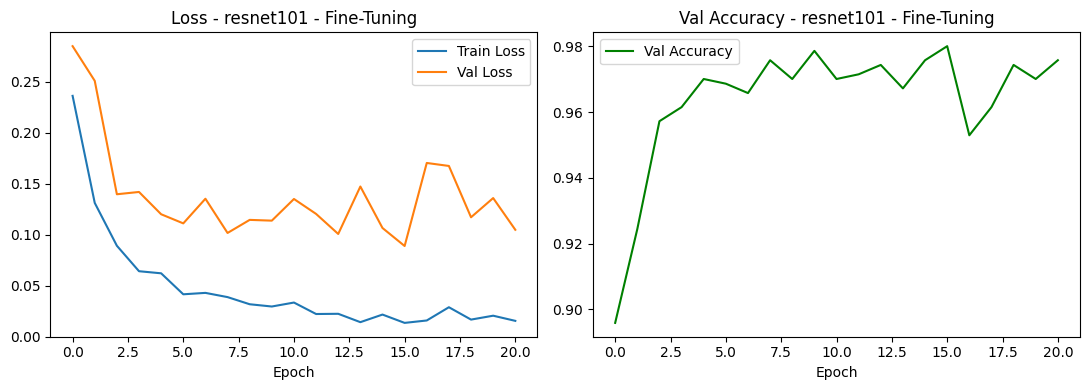


===== HASIL EVALUASI [resnet101 - Sesudah FT] =====
Accuracy : 0.9772
Precision: 0.9780
Recall   : 0.9775
F1-Score : 0.9775

              precision    recall  f1-score   support

      glioma       0.99      0.94      0.97       179
  meningioma       0.94      0.98      0.96       179
     notumor       0.98      0.99      0.99       168
   pituitary       0.99      0.99      0.99       176

    accuracy                           0.98       702
   macro avg       0.98      0.98      0.98       702
weighted avg       0.98      0.98      0.98       702



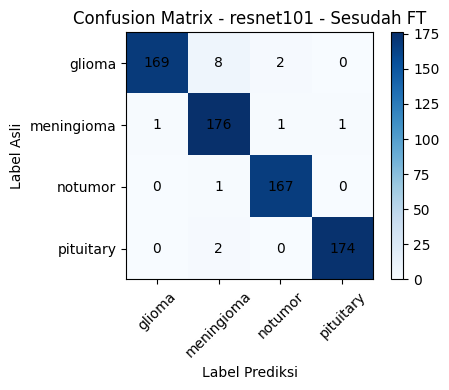


Ringkasan resnet101:
  Sebelum FT -> F1: 0.9277, Accuracy: 0.9274
  Sesudah FT -> F1: 0.9775, Accuracy: 0.9772
  Peningkatan F1  : +0.0498


In [18]:
all_results["resnet101"] = run_or_load("resnet101")

## GoogLeNet


ARSITEKTUR: GOOGLENET
>>> TAHAP 1: Training sebelum fine-tuning (classifier head saja)
[googlenet-before-FT] Epoch 01 | train_loss=0.7444 | val_loss=0.5600 | val_acc=0.8103 | 573.9s
[googlenet-before-FT] Epoch 02 | train_loss=0.5158 | val_loss=0.4817 | val_acc=0.8402 | 580.0s
[googlenet-before-FT] Epoch 03 | train_loss=0.4607 | val_loss=0.4657 | val_acc=0.8160 | 602.5s
[googlenet-before-FT] Epoch 04 | train_loss=0.4326 | val_loss=0.4293 | val_acc=0.8302 | 628.5s
[googlenet-before-FT] Epoch 05 | train_loss=0.4184 | val_loss=0.4062 | val_acc=0.8502 | 679.4s
[googlenet-before-FT] Epoch 06 | train_loss=0.4062 | val_loss=0.4020 | val_acc=0.8388 | 578.7s
[googlenet-before-FT] Epoch 07 | train_loss=0.3879 | val_loss=0.3897 | val_acc=0.8573 | 556.9s
[googlenet-before-FT] Epoch 08 | train_loss=0.3825 | val_loss=0.3670 | val_acc=0.8645 | 562.8s
[googlenet-before-FT] Epoch 09 | train_loss=0.3745 | val_loss=0.3597 | val_acc=0.8688 | 555.2s
[googlenet-before-FT] Epoch 10 | train_loss=0.3758 | val_

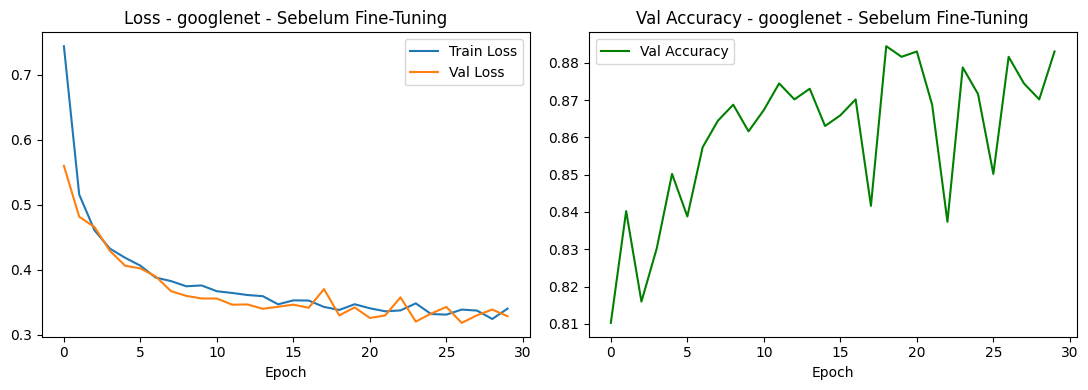


===== HASIL EVALUASI [googlenet - Sebelum FT] =====
Accuracy : 0.8889
Precision: 0.8886
Recall   : 0.8906
F1-Score : 0.8883

              precision    recall  f1-score   support

      glioma       0.83      0.88      0.85       179
  meningioma       0.85      0.74      0.79       179
     notumor       0.94      0.98      0.96       168
   pituitary       0.93      0.96      0.95       176

    accuracy                           0.89       702
   macro avg       0.89      0.89      0.89       702
weighted avg       0.89      0.89      0.89       702



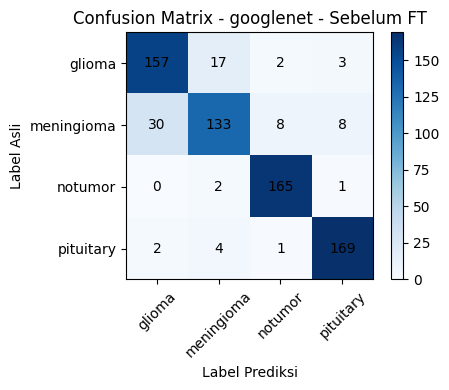

>>> TAHAP 2: Fine-tuning (unfreeze layer konvolusi terdalam)
Trainable parameter setelah unfreeze: 2,330,084
[googlenet-fine-tuning] Epoch 01 | train_loss=0.3394 | val_loss=0.2451 | val_acc=0.9201 | 559.2s
[googlenet-fine-tuning] Epoch 02 | train_loss=0.2206 | val_loss=0.2534 | val_acc=0.9073 | 561.0s
[googlenet-fine-tuning] Epoch 03 | train_loss=0.1748 | val_loss=0.2418 | val_acc=0.9073 | 560.2s
[googlenet-fine-tuning] Epoch 04 | train_loss=0.1481 | val_loss=0.1482 | val_acc=0.9501 | 564.7s
[googlenet-fine-tuning] Epoch 05 | train_loss=0.1205 | val_loss=0.1692 | val_acc=0.9515 | 570.5s
[googlenet-fine-tuning] Epoch 06 | train_loss=0.1023 | val_loss=0.1272 | val_acc=0.9643 | 579.5s
[googlenet-fine-tuning] Epoch 07 | train_loss=0.0845 | val_loss=0.1162 | val_acc=0.9629 | 578.1s
[googlenet-fine-tuning] Epoch 08 | train_loss=0.0745 | val_loss=0.1666 | val_acc=0.9401 | 712.4s
[googlenet-fine-tuning] Epoch 09 | train_loss=0.0714 | val_loss=0.1381 | val_acc=0.9658 | 739.3s
[googlenet-fine-tu

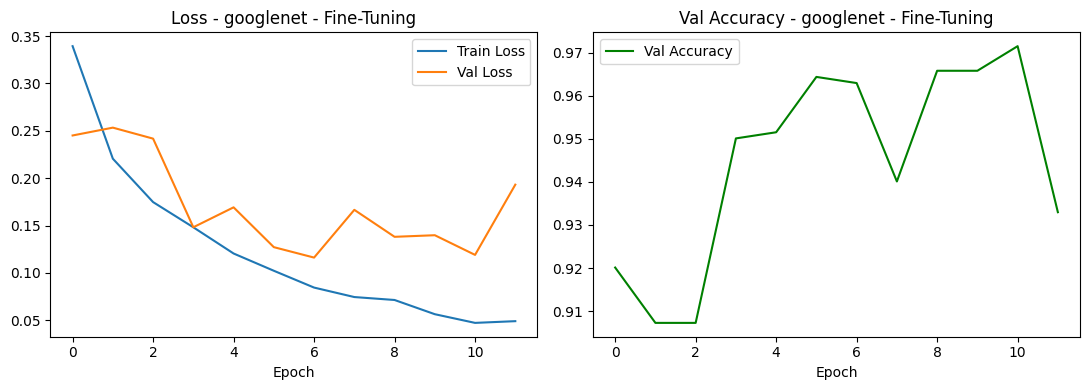


===== HASIL EVALUASI [googlenet - Sesudah FT] =====
Accuracy : 0.9544
Precision: 0.9544
Recall   : 0.9551
F1-Score : 0.9547

              precision    recall  f1-score   support

      glioma       0.94      0.93      0.94       179
  meningioma       0.94      0.92      0.93       179
     notumor       0.97      0.99      0.98       168
   pituitary       0.96      0.98      0.97       176

    accuracy                           0.95       702
   macro avg       0.95      0.96      0.95       702
weighted avg       0.95      0.95      0.95       702



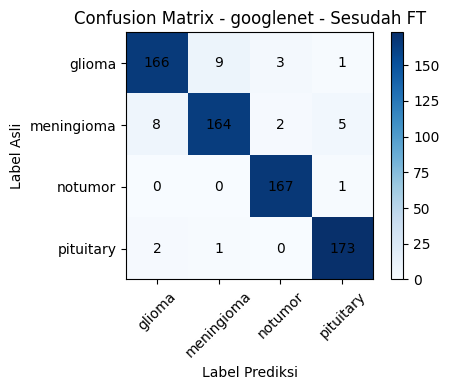


Ringkasan googlenet:
  Sebelum FT -> F1: 0.8883, Accuracy: 0.8889
  Sesudah FT -> F1: 0.9547, Accuracy: 0.9544
  Peningkatan F1  : +0.0663


In [19]:
all_results["googlenet"] = run_or_load("googlenet")

## Ringkasan, Interval Kepercayaan, dan Uji Statistik

In [20]:
ARCHS = ["vgg16", "resnet101", "googlenet"]

rows = []
for arch in ARCHS:
    with open(os.path.join(RESULTS_DIR, f"{arch}_metrics.json"), "r", encoding="utf-8") as f:
        m = json.load(f)
    rows.append({
        "Arsitektur": arch,
        "Acc Sebelum FT": m["before"]["accuracy"],
        "F1 Sebelum FT": m["before"]["f1"],
        "Acc Sesudah FT": m["after"]["accuracy"],
        "F1 Sesudah FT": m["after"]["f1"],
        "Peningkatan F1": m["after"]["f1"] - m["before"]["f1"],
    })

# Prediksi dimuat eksplisit agar sel statistik berikutnya bisa dijalankan berurutan.
preds = {
    arch: np.load(os.path.join(RESULTS_DIR, f"{arch}_preds.npz"), allow_pickle=False)
    for arch in ARCHS
}
reference_labels = preds[ARCHS[0]]["labels"]
for arch in ARCHS[1:]:
    assert np.array_equal(reference_labels, preds[arch]["labels"]), (
        f"Prediksi {arch} memakai urutan/isi test labels yang berbeda."
    )

df_summary = pd.DataFrame(rows).set_index("Arsitektur")
df_summary.to_csv(os.path.join(RESULTS_DIR, "summary.csv"))
df_summary.round(4)


,Acc Sebelum FT,F1 Sebelum FT,Acc Sesudah FT,F1 Sesudah FT,Peningkatan F1
Arsitektur,,,,,
vgg16,0.8803,0.8804,0.9729,0.9732,0.0929
resnet101,0.9274,0.9277,0.9772,0.9775,0.0498
googlenet,0.8889,0.8883,0.9544,0.9547,0.0663


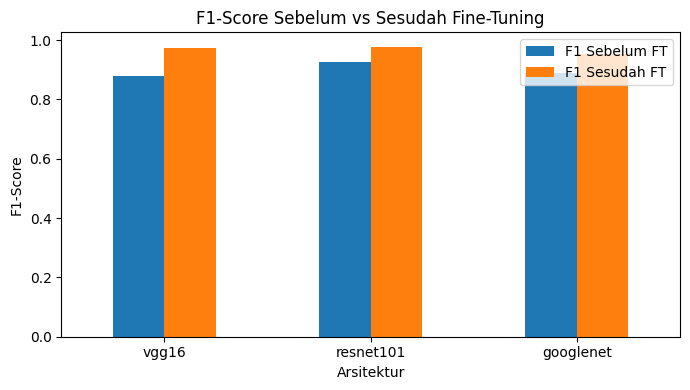

In [21]:
df_summary[["F1 Sebelum FT", "F1 Sesudah FT"]].plot(kind="bar", figsize=(7, 4))
plt.title("F1-Score Sebelum vs Sesudah Fine-Tuning")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Interval kepercayaan dan perbandingan berpasangan

Bootstrap mempertahankan jumlah sampel per kelas dan memakai indeks sampel yang sama saat membandingkan dua prediksi. Uji McNemar exact membandingkan pasangan prediksi pada test set. Hasil ini mendukung interpretasi eksperimen pada split ini; bukan bukti generalisasi ke dataset/pasien lain.


In [22]:
def stratified_bootstrap_indices(labels, rng):
    """Ambil ulang sampel di dalam setiap kelas agar komposisi kelas tetap."""
    sampled = []
    for cls in np.unique(labels):
        class_idx = np.flatnonzero(labels == cls)
        sampled.append(rng.choice(class_idx, size=len(class_idx), replace=True))
    return np.concatenate(sampled)


def bootstrap_metric_ci(labels, pred, metric_fn, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed)
    scores = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        idx = stratified_bootstrap_indices(labels, rng)
        scores[i] = metric_fn(labels[idx], pred[idx])
    return np.percentile(scores, [2.5, 97.5])


def paired_bootstrap_difference_ci(labels, pred_a, pred_b, metric_fn,
                                   n_boot=2000, seed=SEED):
    """CI untuk A-B dengan resampling pasangan sampel yang sama."""
    rng = np.random.default_rng(seed)
    diffs = np.empty(n_boot, dtype=float)
    for i in range(n_boot):
        idx = stratified_bootstrap_indices(labels, rng)
        diffs[i] = metric_fn(labels[idx], pred_a[idx]) - metric_fn(labels[idx], pred_b[idx])
    return np.percentile(diffs, [2.5, 97.5])


def mcnemar_exact(labels, pred_a, pred_b):
    """Uji McNemar exact untuk dua prediksi pada sampel test yang sama."""
    correct_a = pred_a == labels
    correct_b = pred_b == labels
    a_only = int(np.sum(correct_a & ~correct_b))
    b_only = int(np.sum(~correct_a & correct_b))
    discordant = a_only + b_only
    p_value = 1.0 if discordant == 0 else binomtest(
        min(a_only, b_only), n=discordant, p=0.5, alternative="two-sided"
    ).pvalue
    return a_only, b_only, p_value


def holm_adjust(p_values):
    """Koreksi Holm untuk sekumpulan uji dalam satu keluarga perbandingan."""
    p_values = np.asarray(p_values, dtype=float)
    order = np.argsort(p_values)
    adjusted = np.empty_like(p_values)
    running_max = 0.0
    m = len(p_values)
    for rank, idx in enumerate(order):
        running_max = max(running_max, (m - rank) * p_values[idx])
        adjusted[idx] = min(1.0, running_max)
    return adjusted


f1_macro = lambda y, p: f1_score(y, p, average="macro", zero_division=0)

# CI per model dan tahap.
ci_rows = []
for arch in ARCHS:
    y = preds[arch]["labels"]
    for stage in ["before", "after"]:
        p = preds[arch][stage]
        lo_acc, hi_acc = bootstrap_metric_ci(y, p, accuracy_score, seed=SEED)
        lo_f1, hi_f1 = bootstrap_metric_ci(y, p, f1_macro, seed=SEED)
        ci_rows.append({
            "Arsitektur": arch,
            "Tahap": "Sebelum FT" if stage == "before" else "Sesudah FT",
            "Accuracy 95% CI": f"{accuracy_score(y, p):.4f} [{lo_acc:.4f}, {hi_acc:.4f}]",
            "Macro F1 95% CI": f"{f1_macro(y, p):.4f} [{lo_f1:.4f}, {hi_f1:.4f}]",
        })
ci_table = pd.DataFrame(ci_rows).set_index(["Arsitektur", "Tahap"])
display(ci_table)

# Perbandingan sebelum vs sesudah fine-tuning: prediksi berpasangan pada test yang sama.
ft_rows = []
ft_p_values = []
for arch in ARCHS:
    y = preds[arch]["labels"]
    before, after = preds[arch]["before"], preds[arch]["after"]
    lo, hi = paired_bootstrap_difference_ci(y, after, before, f1_macro, seed=SEED)
    a_only, b_only, p_value = mcnemar_exact(y, after, before)
    ft_p_values.append(p_value)
    ft_rows.append({
        "Arsitektur": arch,
        "Delta macro F1 (sesudah-sebelum)": f"{f1_macro(y, after)-f1_macro(y, before):+.4f}",
        "95% CI delta": f"[{lo:+.4f}, {hi:+.4f}]",
        "Sesudah benar, sebelum salah": a_only,
        "Sebelum benar, sesudah salah": b_only,
        "McNemar p (Holm)": p_value,
    })
for row, p_adj in zip(ft_rows, holm_adjust(ft_p_values)):
    row["McNemar p (Holm)"] = p_adj
ft_table = pd.DataFrame(ft_rows).set_index("Arsitektur")
display(ft_table)

# Perbandingan antar-model pada tahap sesudah FT.
model_pairs = [(ARCHS[0], ARCHS[1]), (ARCHS[0], ARCHS[2]), (ARCHS[1], ARCHS[2])]
model_rows = []
model_p_values = []
for model_a, model_b in model_pairs:
    y = preds[model_a]["labels"]
    pred_a, pred_b = preds[model_a]["after"], preds[model_b]["after"]
    lo, hi = paired_bootstrap_difference_ci(y, pred_a, pred_b, f1_macro, seed=SEED)
    a_only, b_only, p_value = mcnemar_exact(y, pred_a, pred_b)
    model_p_values.append(p_value)
    model_rows.append({
        "Perbandingan": f"{model_a} - {model_b}",
        "Delta macro F1": f"{f1_macro(y, pred_a)-f1_macro(y, pred_b):+.4f}",
        "95% CI delta": f"[{lo:+.4f}, {hi:+.4f}]",
        f"{model_a} benar saja": a_only,
        f"{model_b} benar saja": b_only,
        "McNemar p (Holm)": p_value,
    })
for row, p_adj in zip(model_rows, holm_adjust(model_p_values)):
    row["McNemar p (Holm)"] = p_adj
model_comparison_table = pd.DataFrame(model_rows).set_index("Perbandingan")
display(model_comparison_table)


Accuracy 95% CI          Macro F1 95% CI
Arsitektur Tahap                                                       
vgg16      Sebelum FT  0.8803 [0.8547, 0.9031]  0.8804 [0.8551, 0.9033]
           Sesudah FT  0.9729 [0.9601, 0.9843]  0.9732 [0.9606, 0.9844]
resnet101  Sebelum FT  0.9274 [0.9074, 0.9459]  0.9277 [0.9084, 0.9460]
           Sesudah FT  0.9772 [0.9658, 0.9872]  0.9775 [0.9662, 0.9874]
googlenet  Sebelum FT  0.8889 [0.8675, 0.9103]  0.8883 [0.8664, 0.9108]
           Sesudah FT  0.9544 [0.9387, 0.9687]  0.9547 [0.9389, 0.9689]

,Delta macro F1 (sesudah-sebelum),95% CI delta,"Sesudah benar, sebelum salah","Sebelum benar, sesudah salah",McNemar p (Holm)
Arsitektur,,,,,
vgg16,+0.0929,"[+0.0691, +0.1179]",73,8,8.931909e-14
resnet101,+0.0498,"[+0.0340, +0.0662]",37,2,2.841261e-09
googlenet,+0.0663,"[+0.0462, +0.0868]",51,5,2.340585e-10


,Delta macro F1,95% CI delta,vgg16 benar saja,resnet101 benar saja,McNemar p (Holm),googlenet benar saja
Perbandingan,,,,,,
vgg16 - resnet101,-0.0042,"[-0.0156, +0.0070]",7.0,10.0,0.629059,NaN
vgg16 - googlenet,+0.0186,"[+0.0030, +0.0341]",22.0,NaN,0.058899,9.0
resnet101 - googlenet,+0.0228,"[+0.0100, +0.0368]",NaN,20.0,0.004632,4.0


### Ringkasan

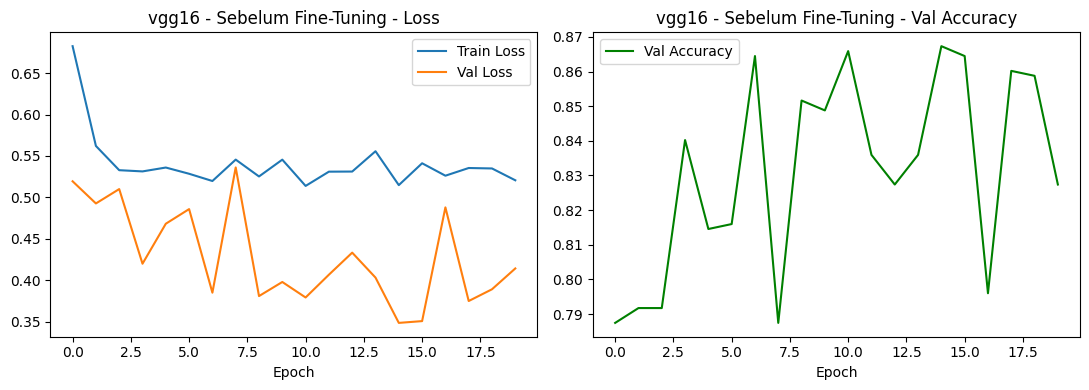

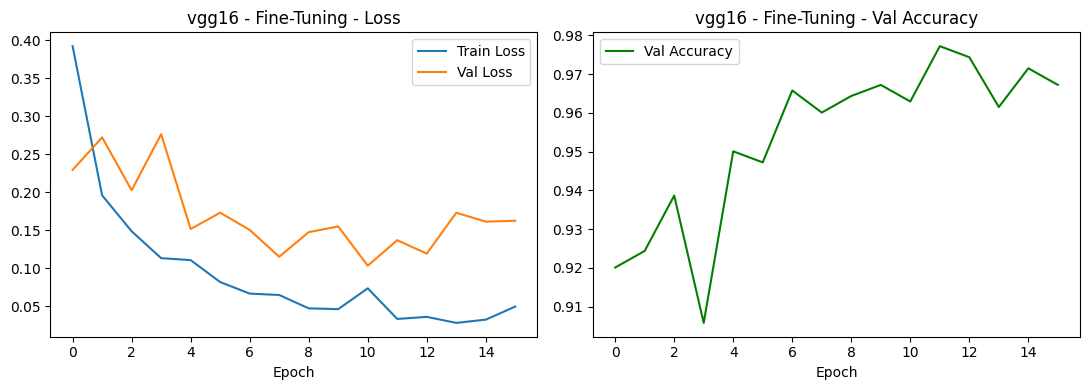

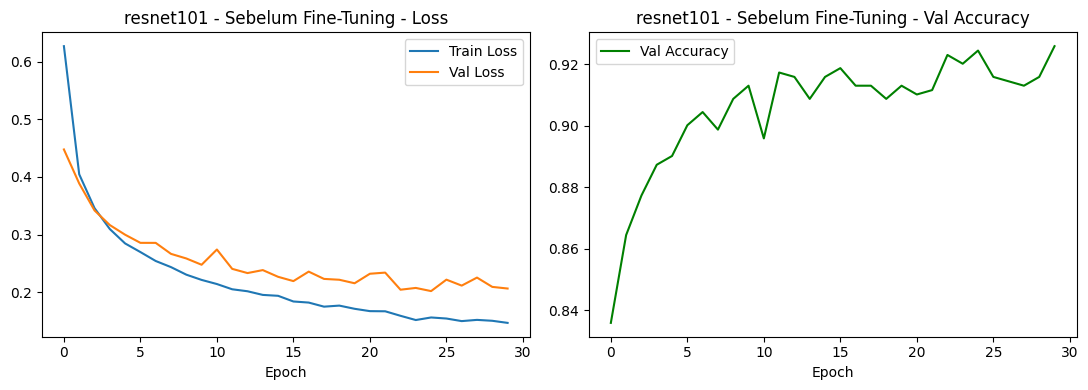

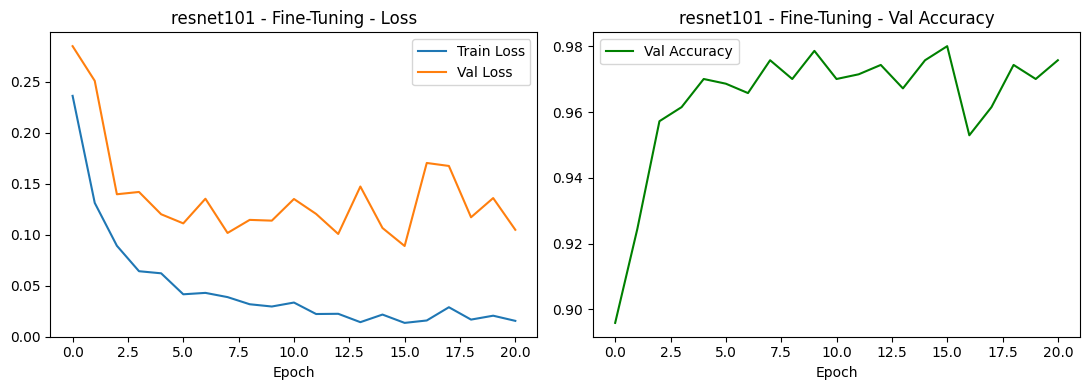

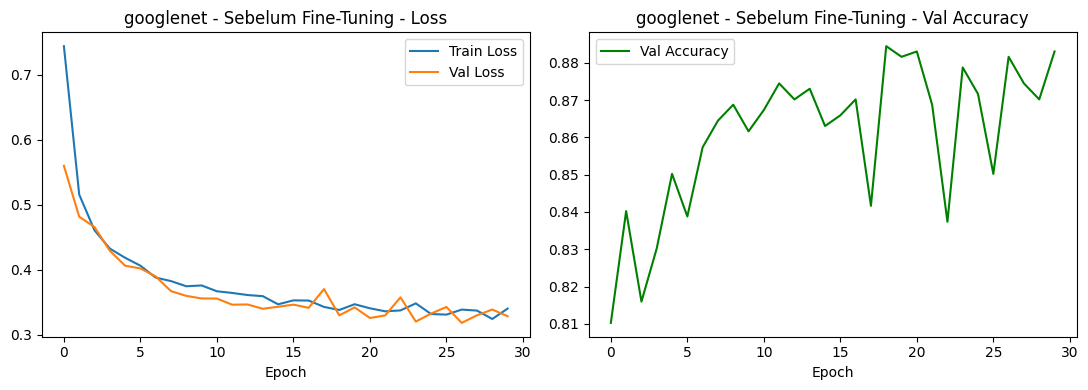

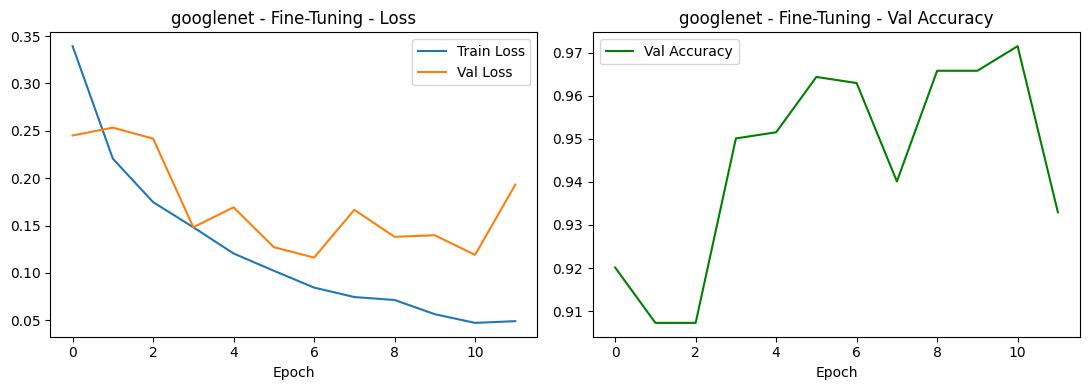

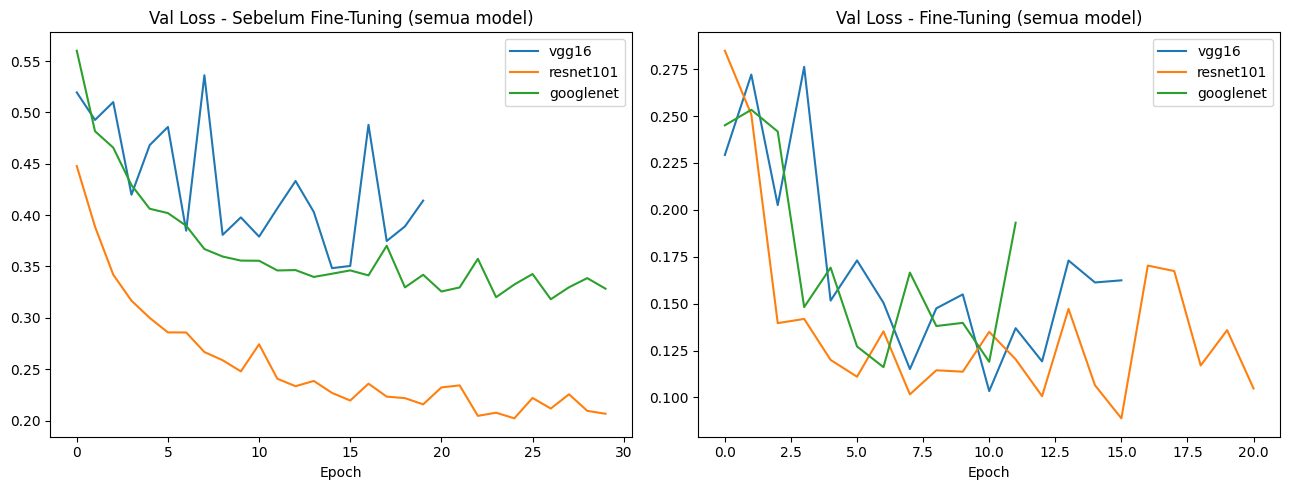

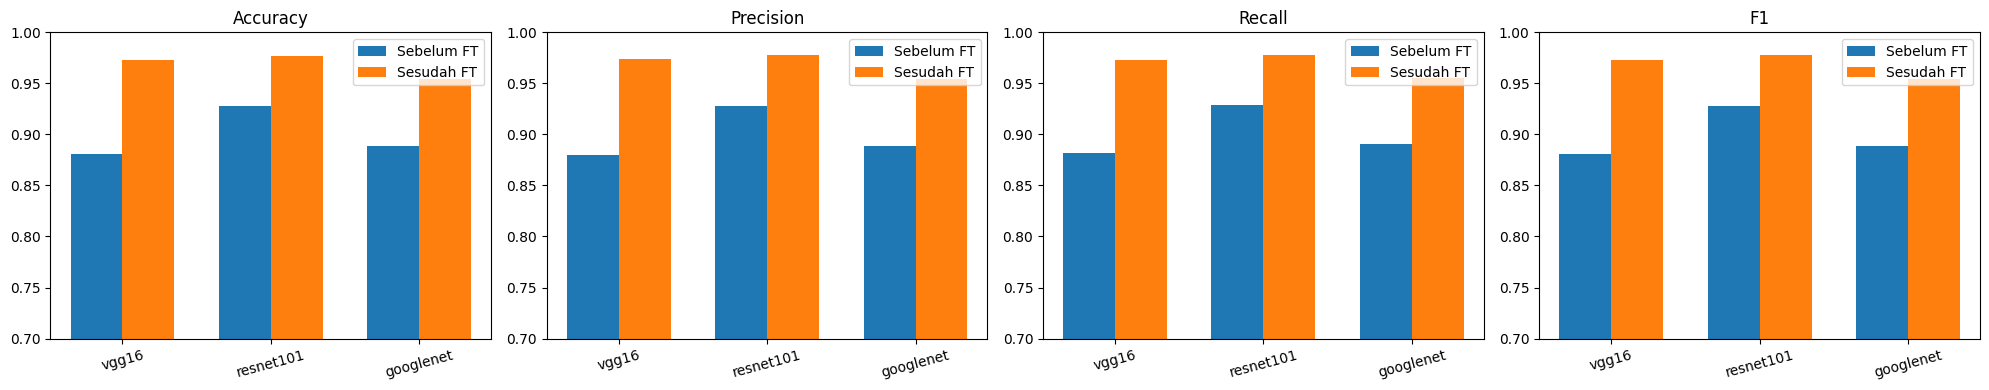

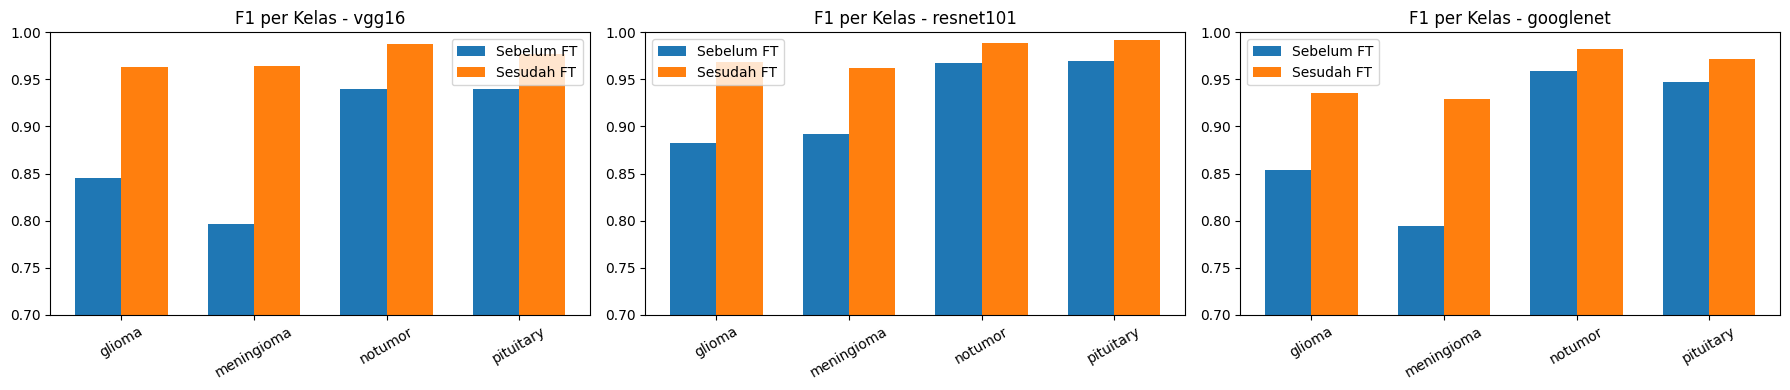

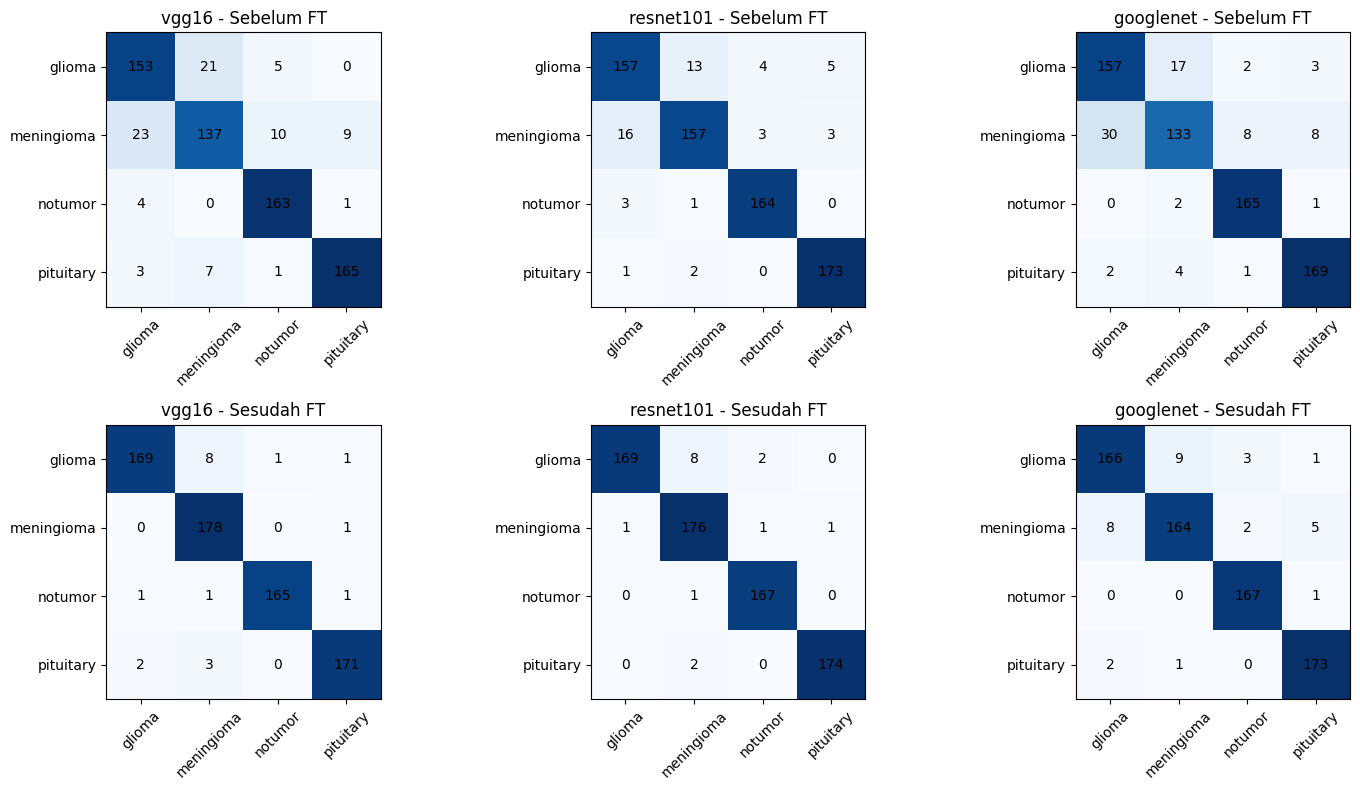

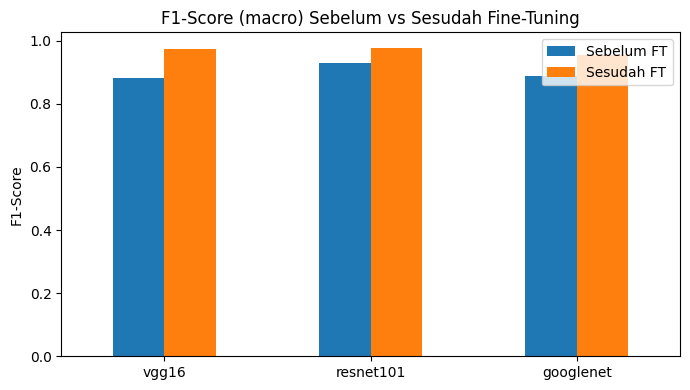

In [23]:
import os, json
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

ARCHS = ["vgg16", "resnet101", "googlenet"]

with open(os.path.join(RESULTS_DIR, "class_names.json"), encoding="utf-8") as f:
    class_names = json.load(f)

metrics = {a: json.load(open(os.path.join(RESULTS_DIR, f"{a}_metrics.json"), encoding="utf-8")) for a in ARCHS}
history = {a: json.load(open(os.path.join(RESULTS_DIR, f"{a}_history.json"), encoding="utf-8")) for a in ARCHS}
preds = {a: np.load(os.path.join(RESULTS_DIR, f"{a}_preds.npz")) for a in ARCHS}

# ===== 1. Kurva training tiap model: sebelum FT & fine-tuning (loss + accuracy) =====
for arch in ARCHS:
    for stage, label in [("before", "Sebelum Fine-Tuning"), ("ft", "Fine-Tuning")]:
        h = history[arch][stage]
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        axes[0].plot(h["train_loss"], label="Train Loss")
        axes[0].plot(h["val_loss"], label="Val Loss")
        axes[0].set_title(f"{arch} - {label} - Loss")
        axes[0].set_xlabel("Epoch")
        axes[0].legend()

        axes[1].plot(h["val_acc"], label="Val Accuracy", color="green")
        axes[1].set_title(f"{arch} - {label} - Val Accuracy")
        axes[1].set_xlabel("Epoch")
        axes[1].legend()
        plt.tight_layout()
        plt.show()

# ===== 2. Semua kurva val_loss dalam satu grafik (bandingkan konvergensi antar model) =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for arch in ARCHS:
    axes[0].plot(history[arch]["before"]["val_loss"], label=arch)
    axes[1].plot(history[arch]["ft"]["val_loss"], label=arch)
axes[0].set_title("Val Loss - Sebelum Fine-Tuning (semua model)")
axes[0].set_xlabel("Epoch"); axes[0].legend()
axes[1].set_title("Val Loss - Fine-Tuning (semua model)")
axes[1].set_xlabel("Epoch"); axes[1].legend()
plt.tight_layout()
plt.show()

# ===== 3. Bar chart Accuracy, Precision, Recall, F1 - semua model, sebelum vs sesudah =====
metric_names = ["accuracy", "precision", "recall", "f1"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
x = np.arange(len(ARCHS))
width = 0.35
for i, mname in enumerate(metric_names):
    before_vals = [metrics[a]["before"][mname] for a in ARCHS]
    after_vals = [metrics[a]["after"][mname] for a in ARCHS]
    axes[i].bar(x - width/2, before_vals, width, label="Sebelum FT")
    axes[i].bar(x + width/2, after_vals, width, label="Sesudah FT")
    axes[i].set_title(mname.capitalize())
    axes[i].set_xticks(x); axes[i].set_xticklabels(ARCHS, rotation=15)
    axes[i].set_ylim(0.7, 1.0)
    axes[i].legend()
plt.tight_layout()
plt.show()

# ===== 4. F1 per kelas - sebelum vs sesudah, tiap model (grouped bar) =====
fig, axes = plt.subplots(1, len(ARCHS), figsize=(6 * len(ARCHS), 4))
for ax, arch in zip(axes, ARCHS):
    rep_before = classification_report(preds[arch]["labels"], preds[arch]["before"],
                                        target_names=class_names, output_dict=True, zero_division=0)
    rep_after = classification_report(preds[arch]["labels"], preds[arch]["after"],
                                       target_names=class_names, output_dict=True, zero_division=0)
    f1_before = [rep_before[c]["f1-score"] for c in class_names]
    f1_after = [rep_after[c]["f1-score"] for c in class_names]
    xc = np.arange(len(class_names))
    ax.bar(xc - width/2, f1_before, width, label="Sebelum FT")
    ax.bar(xc + width/2, f1_after, width, label="Sesudah FT")
    ax.set_title(f"F1 per Kelas - {arch}")
    ax.set_xticks(xc); ax.set_xticklabels(class_names, rotation=30)
    ax.set_ylim(0.7, 1.0)
    ax.legend()
plt.tight_layout()
plt.show()

# ===== 5. Confusion matrix semua model, sebelum vs sesudah (2 baris x 3 kolom) =====
fig, axes = plt.subplots(2, len(ARCHS), figsize=(5 * len(ARCHS), 8))
for col, arch in enumerate(ARCHS):
    for row, (stage, label) in enumerate([("before", "Sebelum FT"), ("after", "Sesudah FT")]):
        cm = confusion_matrix(preds[arch]["labels"], preds[arch][stage])
        ax = axes[row, col]
        ax.imshow(cm, cmap="Blues")
        ax.set_title(f"{arch} - {label}")
        ax.set_xticks(range(len(class_names))); ax.set_xticklabels(class_names, rotation=45)
        ax.set_yticks(range(len(class_names))); ax.set_yticklabels(class_names)
        for i in range(len(class_names)):
            for j in range(len(class_names)):
                ax.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

# ===== 6. F1-Score keseluruhan (macro) - bar chart utama =====
df_f1 = pd.DataFrame({
    "Sebelum FT": [metrics[a]["before"]["f1"] for a in ARCHS],
    "Sesudah FT": [metrics[a]["after"]["f1"] for a in ARCHS],
}, index=ARCHS)
df_f1.plot(kind="bar", figsize=(7, 4))
plt.title("F1-Score (macro) Sebelum vs Sesudah Fine-Tuning")
plt.ylabel("F1-Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()